In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [9]:
df=pd.read_csv("linear_regression_data.csv")
df.head()

,study_hours,exam_score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,65


Text(0, 0.5, 'Exam Score')

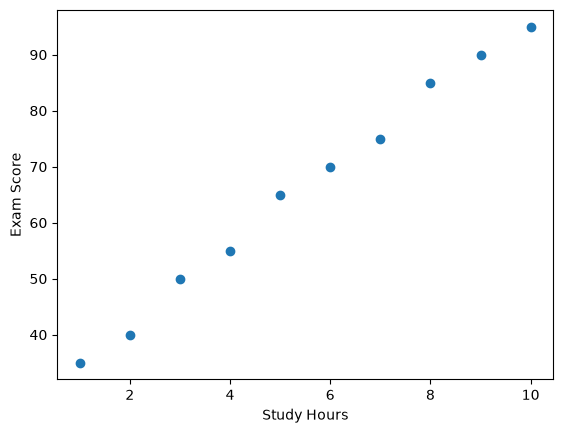

In [10]:
plt.scatter(df['study_hours'], df['exam_score'])
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

In [11]:
df.corr()

,study_hours,exam_score
study_hours,1.000000,0.997348
exam_score,0.997348,1.000000


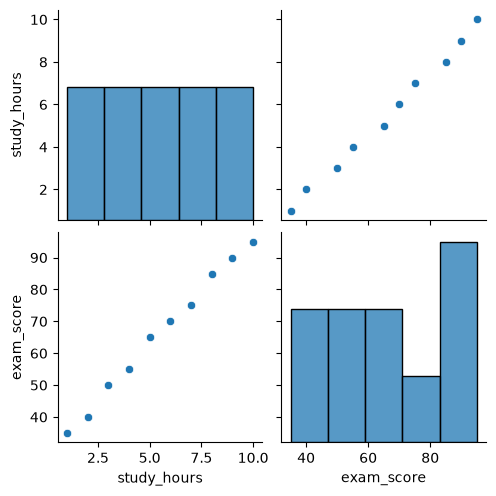

In [12]:
import seaborn as sns
sns.pairplot(df)

In [13]:
X=df[['study_hours']]
y=df['exam_score']
np.array(X).shape
np.array(y).shape

(10,)

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.2, random_state=42)



In [16]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

In [17]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [19]:
from sklearn.linear_model import LinearRegression

regression=LinearRegression(n_jobs=-1)

In [20]:
regression.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[18.11]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,66.25
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[2.83]


In [24]:
print("Coefficient of slope:",regression.coef_)

print("Interciepts:", regression.intercept_)

Coefficient of slope: [18.10529547]
Interciepts: 66.25


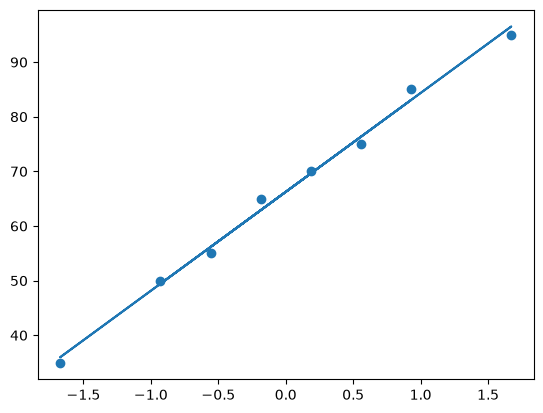

In [27]:
plt.scatter(X_train,y_train)

plt.plot(X_train, regression.predict(X_train))

In [28]:
## Prediction for test data 

y_pred= regression.predict(X_test)

In [29]:
## calculation of importing 
from sklearn.metrics import mean_absolute_error, mean_squared_error

mse=mean_squared_error(y_test, y_pred)
mae=mean_absolute_error(y_test, y_pred)
rmse=np.sqrt(mse)

print(mse)
print(mae)
print(rmse)

3.7102407847800203
1.465517241379306
1.9261985320262345


In [32]:
from sklearn.metrics import r2_score

score= r2_score(y_test, y_pred)
print(score)

0.994063614744352


In [36]:
#display adjusted R-squared 

1-(1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

ZeroDivisionError: division by zero

In [42]:
regression.predict(scaler.transform([[6]]))

d:\Learning\Machine Learning\final_env\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([69.61206897])

In [38]:
print(df.head())

   study_hours  exam_score
0            1          35
1            2          40
2            3          50
3            4          55
4            5          65


In [45]:
##OLS method 

import statsmodels.api as sm

In [52]:
model = sm.OLS(y_train, X_train).fit()
prediction= model.predict(X_test)
print(prediction)


[ 23.53448276 -23.53448276]


In [53]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:             exam_score   R-squared (uncentered):                   0.069
Model:                            OLS   Adj. R-squared (uncentered):             -0.063
Method:                 Least Squares   F-statistic:                             0.5226
Date:                Sun, 11 Oct 2026   Prob (F-statistic):                       0.493
Time:                        00:15:20   Log-Likelihood:                         -44.901
No. Observations:                   8   AIC:                                      91.80
Df Residuals:                       7   BIC:                                      91.88
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [54]:
regression.predict(scaler.transform([[4]]))

d:\Learning\Machine Learning\final_env\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([56.1637931])

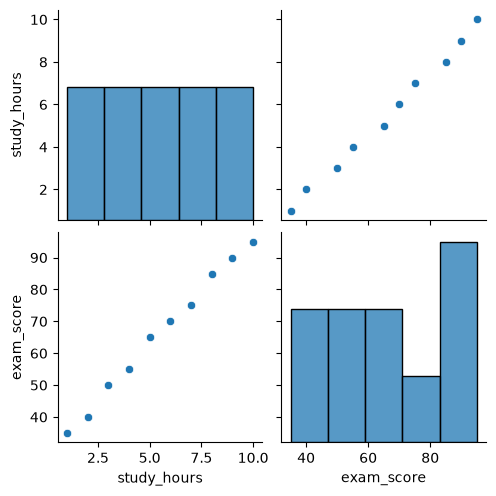